# Visualização com matplotlib — Titanic

Atividade da Aula 5 (Dados 2) da Trilha UFPE.

Continuando com o mesmo dataset da aula anterior. A ideia agora é responder três perguntas com gráficos:

1. **Comparação:** quais grupos de passageiros mais e menos sobreviveram?
2. **Relação:** o tamanho da família que viajava junto tem relação com a chance de sobreviver?
3. **Distribuição:** como se distribuem as tarifas em cada classe e onde estão os valores fora da curva?

## Preparando os dados

Mesma limpeza da aula 1: remover `Cabin`, preencher `Embarked` com o porto mais comum e `Age` com a mediana por classe e sexo.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df = df.drop(columns="Cabin")
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))
df["Survived"] = df["Survived"].astype(bool)

df.isna().sum().sum(), df.shape

(np.int64(0), (891, 11))

In [2]:
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

CINZA = "#cbd5e1"
FOCO = "#d8833b"
ESCURO = "#131b2e"

## Pergunta 1 — Comparação: quais grupos mais e menos sobreviveram?

In [3]:
df["grupo"] = df["Sex"].map({"female": "Mulheres", "male": "Homens"}) + " — " + df["Pclass"].astype(str) + "ª classe"

taxas = (
    df.groupby("grupo")["Survived"]
    .agg(["mean", "count"])
    .sort_values("mean")
)
taxas["mean"] = taxas["mean"] * 100
taxas

,mean,count
grupo,,
Homens — 3ª classe,13.544669,347
Homens — 2ª classe,15.740741,108
Homens — 1ª classe,36.885246,122
Mulheres — 3ª classe,50.000000,144
Mulheres — 2ª classe,92.105263,76
Mulheres — 1ª classe,96.808511,94


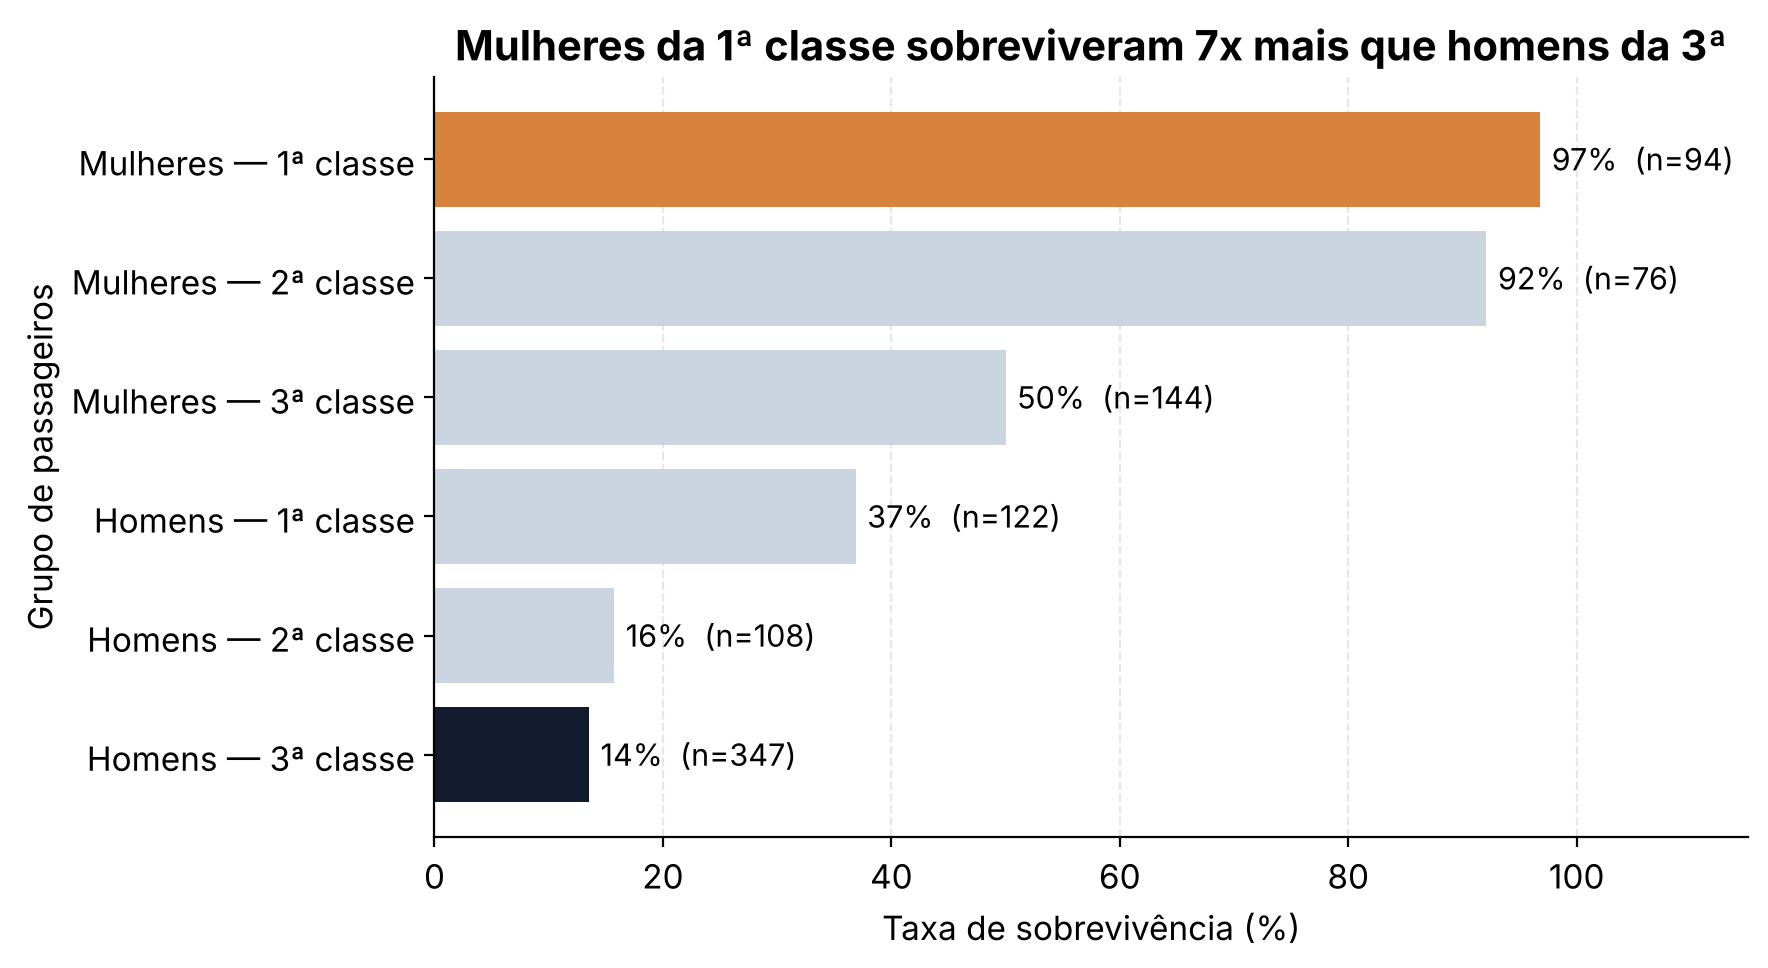

In [4]:
cores = [CINZA] * len(taxas)
cores[0] = ESCURO
cores[-1] = FOCO

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(taxas.index, taxas["mean"], color=cores)

for barra, (taxa, n) in zip(barras, zip(taxas["mean"], taxas["count"])):
    ax.text(barra.get_width() + 1, barra.get_y() + barra.get_height() / 2,
            f"{taxa:.0f}%  (n={n})", va="center", fontsize=11)

ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.set_title("Mulheres da 1ª classe sobreviveram 7x mais que homens da 3ª")
ax.set_xlabel("Taxa de sobrevivência (%)")
ax.set_ylabel("Grupo de passageiros")
ax.grid(axis="x", alpha=0.3, ls="--")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

O gráfico ordena os seis grupos (sexo + classe) pela taxa de sobrevivência. O grupo que mais sobreviveu foi o das mulheres da 1ª classe (97%), e o que menos sobreviveu foi o dos homens da 3ª classe (14%), que também era o grupo mais numeroso do navio (347 pessoas). Todos os grupos de mulheres ficam acima de todos os grupos de homens, então o sexo pesa mais que a classe. Mas dentro de cada sexo a classe também faz diferença: as mulheres da 3ª classe tiveram metade da chance das outras mulheres, e os homens da 1ª classe sobreviveram mais que o dobro dos homens das outras classes.

## Pergunta 2 — Relação: o tamanho da família tem relação com a sobrevivência?

Juntei `SibSp` (irmãos/cônjuge) e `Parch` (pais/filhos) numa coluna com o tamanho total do grupo familiar, contando a própria pessoa. Famílias com 8 ou mais pessoas eram muito poucas, então juntei todas numa categoria só.

In [5]:
df["familia"] = (df["SibSp"] + df["Parch"] + 1).clip(upper=8)

por_familia = df.groupby("familia")["Survived"].agg(["mean", "count"])
por_familia["mean"] = por_familia["mean"] * 100
por_familia

,mean,count
familia,,
1,30.353818,537
2,55.279503,161
3,57.843137,102
4,72.413793,29
5,20.000000,15
6,13.636364,22
7,33.333333,12
8,0.000000,13


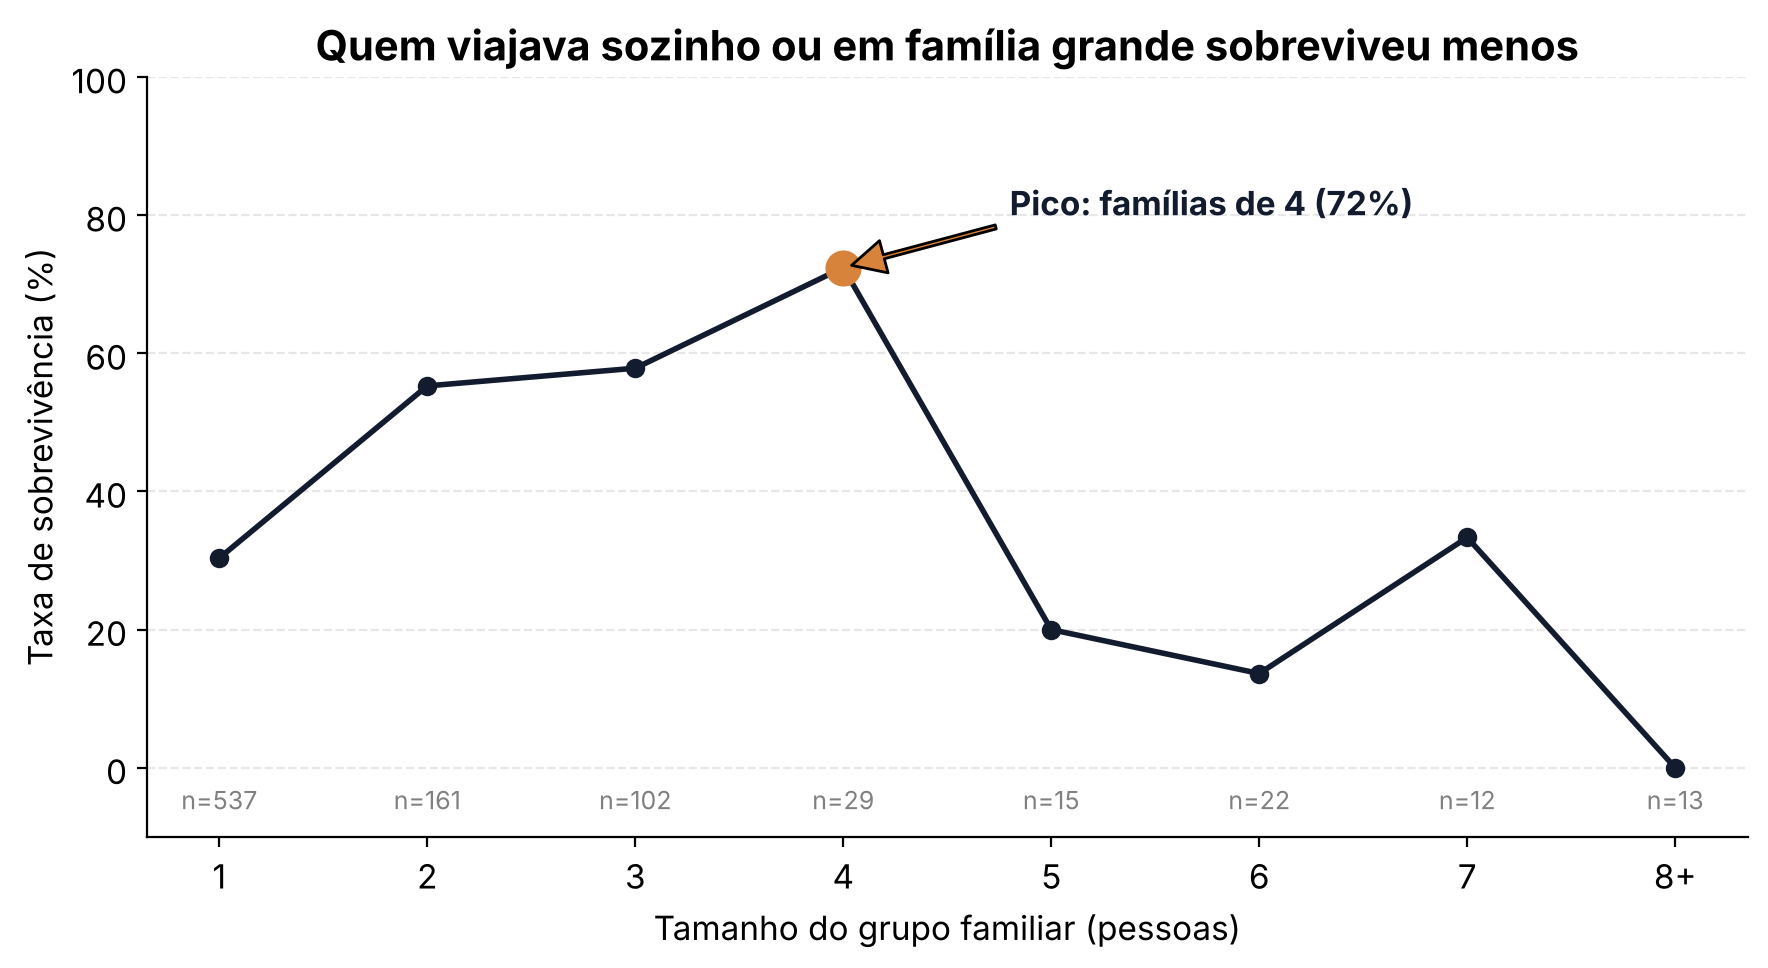

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(por_familia.index, por_familia["mean"], marker="o", color=ESCURO, lw=2)

pico = por_familia["mean"].idxmax()
ax.plot(pico, por_familia.loc[pico, "mean"], marker="o", markersize=12, color=FOCO)
ax.annotate(f"Pico: famílias de {pico} ({por_familia.loc[pico, 'mean']:.0f}%)",
            xy=(pico, por_familia.loc[pico, "mean"]), xytext=(pico + 0.8, 80),
            arrowprops=dict(facecolor=FOCO, shrink=0.05, width=1.5),
            fontweight="bold", color=ESCURO)

for x, (taxa, n) in por_familia.iterrows():
    ax.text(x, -6, f"n={int(n)}", ha="center", fontsize=9, color="gray")

ax.set_ylim(-10, 100)
ax.set_xticks(por_familia.index)
ax.set_xticklabels([str(i) if i < 8 else "8+" for i in por_familia.index])
ax.set_title("Quem viajava sozinho ou em família grande sobreviveu menos")
ax.set_xlabel("Tamanho do grupo familiar (pessoas)")
ax.set_ylabel("Taxa de sobrevivência (%)")
ax.grid(axis="y", alpha=0.3, ls="--")
plt.tight_layout()
plt.show()

A relação não é uma linha reta: a chance de sobreviver sobe de quem viajava sozinho (30%) até famílias de 4 pessoas (72%) e depois despenca: nas famílias de 5 pessoas ou mais fica entre 0% e 33%, e nenhum passageiro de família com 8 ou mais sobreviveu. Quem viajava sozinho era a maioria (537 pessoas) e muitos eram homens da 3ª classe, o que ajuda a explicar a taxa baixa. Já as famílias grandes estavam quase todas na 3ª classe e provavelmente tiveram dificuldade de se manter juntas e chegar aos botes. Vale lembrar que os grupos de 5 pessoas para cima têm poucos passageiros (os valores de `n` no gráfico), então essas taxas variam muito com poucas pessoas a mais ou a menos.

## Pergunta 3 — Distribuição: como as tarifas se distribuem em cada classe?

In [7]:
df.groupby("Pclass")["Fare"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.15,78.38,0.0,30.92,60.29,93.5,512.33
2,184.0,20.66,13.42,0.0,13.00,14.25,26.0,73.50
3,491.0,13.68,11.78,0.0,7.75,8.05,15.5,69.55


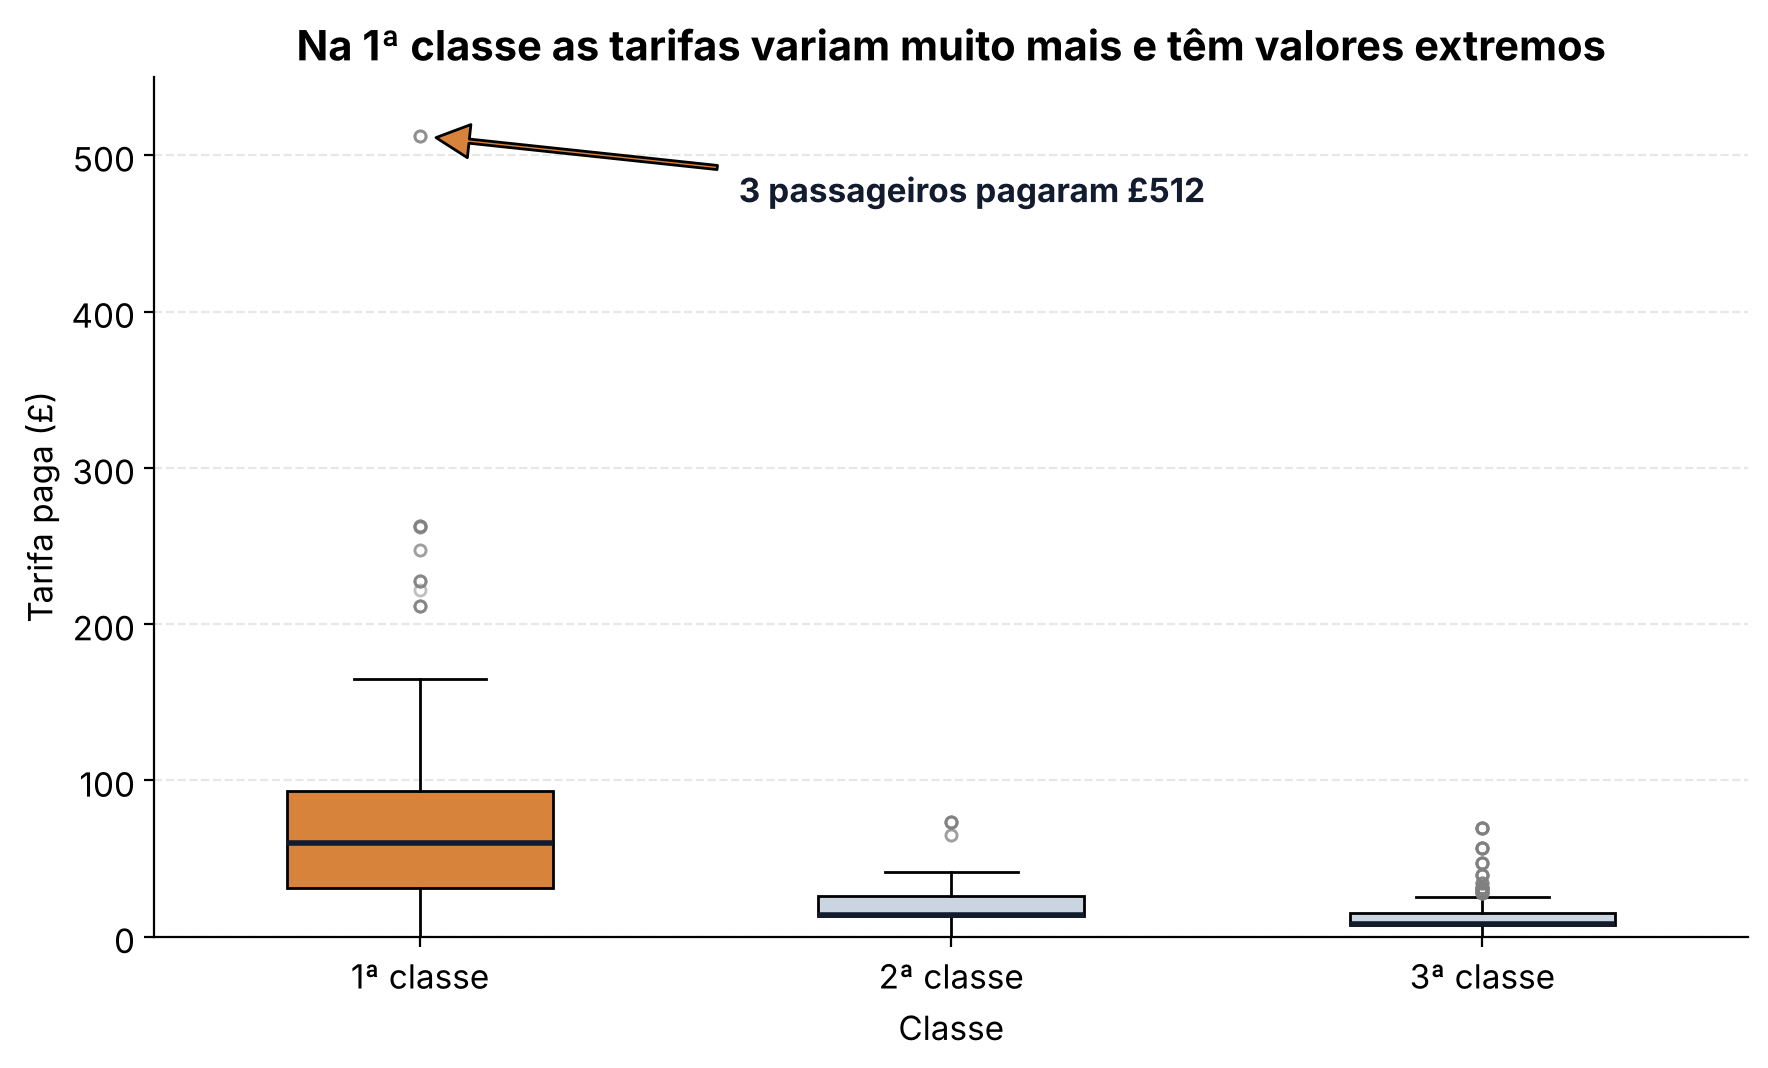

In [8]:
classes = [1, 2, 3]
tarifas = [df.loc[df["Pclass"] == cl, "Fare"] for cl in classes]

fig, ax = plt.subplots(figsize=(9, 5.5))
caixas = ax.boxplot(tarifas, patch_artist=True, widths=0.5,
                    medianprops=dict(color=ESCURO, lw=2),
                    flierprops=dict(marker="o", markersize=4, alpha=0.5, markeredgecolor="gray"))
for caixa, cor in zip(caixas["boxes"], [FOCO, CINZA, CINZA]):
    caixa.set_facecolor(cor)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["1ª classe", "2ª classe", "3ª classe"])

maximo = df["Fare"].max()
ax.annotate(f"3 passageiros pagaram £{maximo:.0f}",
            xy=(1, maximo), xytext=(1.6, 470),
            arrowprops=dict(facecolor=FOCO, shrink=0.05, width=1.5),
            fontweight="bold", color=ESCURO)

ax.set_ylim(0, 550)
ax.set_title("Na 1ª classe as tarifas variam muito mais e têm valores extremos")
ax.set_xlabel("Classe")
ax.set_ylabel("Tarifa paga (£)")
ax.grid(axis="y", alpha=0.3, ls="--")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [9]:
df[df["Fare"] == df["Fare"].max()][["Name", "Pclass", "Fare", "Ticket", "Survived"]]

,Name,Pclass,Fare,Ticket,Survived
258,"Ward, Miss. Anna",1,512.3292,PC 17755,True
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755,True
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755,True


In [10]:
(df["Fare"] == 0).sum()

np.int64(15)

Cada caixa mostra onde está a metade do meio das tarifas de uma classe, a linha dentro dela é a mediana e os pontos são os valores atípicos. Na 2ª e na 3ª classe as tarifas são baixas e concentradas (medianas de £14 e £8). Na 1ª classe a caixa é bem maior: metade dos passageiros pagou entre £31 e £93, e ainda tem vários outliers acima disso, incluindo 3 pessoas que pagaram £512, todas no mesmo bilhete e todas sobreviveram. Isso explica por que, na aula anterior, a média da tarifa da 1ª classe (£84) ficou tão acima da mediana (£60). Também aparecem algumas tarifas iguais a zero, que podem ser funcionários ou passagens cortesia, não necessariamente erro.

## Resumo

- **Comparação:** o sexo foi o fator mais forte, mas a classe também separou bastante quem sobreviveu de quem não sobreviveu.
- **Relação:** viajar com uma família pequena (2 a 4 pessoas) foi associado a mais chance de sobreviver; sozinho ou em família grande, menos.
- **Distribuição:** as tarifas da 1ª classe são muito mais espalhadas e cheias de outliers, por isso a mediana descreve melhor o passageiro típico do que a média.